# Tox21 · Member 2: Morgan fingerprints, descriptors and Logistic Regression baseline

**Self-contained Google Colab notebook.** It needs only Member 1's frozen split files:
`tox21_train.csv`, `tox21_val.csv`, `tox21_test.csv` (and optionally `tox21_clean.csv` for an extra cross-check).

**How to run:** *Runtime → Run all*. When step 1 asks, upload the CSV files. The whole notebook takes a few minutes on a free Colab CPU.

Project rules this notebook follows:
* Member 1's split is only **read and verified**, never changed. Scaffolds must not overlap between train, validation and test.
* **Missing labels stay missing.** Each endpoint is trained and evaluated only on molecules with an observed label.
* Preprocessing (descriptor imputation and scaling) is fitted on **training rows only**.
* Hyperparameters are chosen on **validation ROC-AUC** (the team-wide selection metric). The **test set is used only once, for reporting**.
* Seed = 42. Every number shown is computed from the uploaded data.

The models predict **in-vitro Tox21 assay activity**. They are not definitive statements about human toxicity.

## 0. Install and import

In [1]:
import sys, subprocess
try:
    import rdkit
except ImportError:                      # Colab does not ship RDKit
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rdkit"])
    import rdkit

import io, json, logging, math, os, re, shutil, warnings
from dataclasses import dataclass, field
from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from joblib import Parallel, delayed
from rdkit import Chem, RDLogger
from rdkit.Chem import Crippen, Descriptors, Draw, Lipinski, rdFingerprintGenerator, rdMolDescriptors
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s", force=True)
logger = logging.getLogger("member2")
pd.set_option("display.width", 160)
print({"python": sys.version.split()[0], "rdkit": rdkit.__version__, "scikit-learn": sklearn.__version__,
       "numpy": np.__version__, "pandas": pd.__version__})

{'python': '3.13.9', 'rdkit': '2026.09.1', 'scikit-learn': '1.6.1', 'numpy': '2.5.4', 'pandas': '3.1.0'}


### Settings
Change these only if the team agrees. The fingerprint settings must be the same for Logistic Regression, Random Forest and XGBoost.

In [2]:
SEED = 42
RADIUS = 2                    # Morgan radius (2 is comparable to ECFP4)
N_BITS = 2048                 # fingerprint length
C_GRID = [0.001, 0.01, 0.1, 1.0, 10.0]       # inverse regularisation strength
CLASS_WEIGHTS = [None, "balanced"]
SELECTION_METRIC = "roc_auc"  # team decision: choose settings on validation ROC-AUC
FALLBACK_PARAMS = {"C": 1.0, "class_weight": "balanced"}   # used only if validation has one class
FEATURE_SETS = ["morgan", "descriptors", "morgan+descriptors"]
MAX_ITER = 5000
N_JOBS = -1                   # parallel fits during tuning; results do not depend on it

TASKS = ["NR-AR", "NR-AR-LBD", "NR-AhR", "NR-Aromatase", "NR-ER", "NR-ER-LBD",
         "NR-PPAR-gamma", "SR-ARE", "SR-ATAD5", "SR-HSE", "SR-MMP", "SR-p53"]
SPLITS = ["train", "val", "test"]

OUTPUT_DIR = Path("results/logistic_regression")
MODEL_DIR = Path("models/logistic_regression")
FEATURE_DIR = Path("features")

## 1. Get Member 1's data
In Colab, an upload button appears if the files are not already in `/content/tox21_data`.
*Alternative:* mount Google Drive (`from google.colab import drive; drive.mount('/content/drive')`) and set `DATA_DIR` to the Drive folder that holds the CSVs.

In [3]:
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

DATA_DIR = Path("/content/tox21_data") if IN_COLAB else Path(os.environ.get("TOX21_DATA_DIR", "."))
REQUIRED_FILES = [f"tox21_{s}.csv" for s in SPLITS]

def missing_files():
    return [f for f in REQUIRED_FILES if not (DATA_DIR / f).is_file()]

if missing_files() and IN_COLAB:
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    print("Please upload:", ", ".join(REQUIRED_FILES), "(and optionally tox21_clean.csv)")
    for name, content in colab_files.upload().items():
        clean_name = re.sub(r" \(\d+\)(?=\.csv$)", "", Path(name).name)   # "tox21_train (1).csv" -> "tox21_train.csv"
        (DATA_DIR / clean_name).write_bytes(content)

if missing_files():
    raise FileNotFoundError(f"Missing {missing_files()} in {DATA_DIR.resolve()}")
print("Data folder:", DATA_DIR.resolve(), "|", sorted(p.name for p in DATA_DIR.glob("*.csv")))

Data folder: ./ | ['tox21_clean.csv', 'tox21_test.csv', 'tox21_train.csv', 'tox21_val.csv']


## 2. Load and verify the frozen split
This only **reads** Member 1's files. If any check fails, the notebook stops instead of training on a changed split.

In [4]:
class SplitIntegrityError(ValueError):
    pass

def read_tox21_csv(path: Path) -> pd.DataFrame:
    """Read one split file. Labels stay float so missing values remain NaN (never 0)."""
    df = pd.read_csv(path, dtype={"mol_id": str, "smiles": str, "scaffold": str, "split": str})
    missing = [c for c in ["mol_id", "smiles", "scaffold", "split", *TASKS] if c not in df.columns]
    if missing:
        raise SplitIntegrityError(f"{path.name} is missing columns {missing}")
    df["scaffold"] = df["scaffold"].fillna("")   # acyclic molecules have an empty scaffold
    df[TASKS] = df[TASKS].astype(float)
    return df

def verify_frozen_splits(splits: Dict[str, pd.DataFrame], clean_df: Optional[pd.DataFrame] = None) -> None:
    for name, df in splits.items():
        if (df["split"] != name).any():
            raise SplitIntegrityError(f"Rows in tox21_{name}.csv are labelled with another split")
        if df["mol_id"].duplicated().any():
            raise SplitIntegrityError(f"Duplicate mol_id in {name}")
        values = df[TASKS].to_numpy()
        if not np.isin(values[~np.isnan(values)], (0.0, 1.0)).all():
            raise SplitIntegrityError(f"{name} has labels other than 0, 1 or NaN")
    for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
        if set(splits[a]["mol_id"]) & set(splits[b]["mol_id"]):
            raise SplitIntegrityError(f"mol_ids shared by {a} and {b}")
        shared = set(splits[a]["scaffold"]) & set(splits[b]["scaffold"])
        if shared:
            raise SplitIntegrityError(f"{len(shared)} scaffolds shared by {a} and {b}")
    if clean_df is not None:
        for name in SPLITS:
            if set(clean_df.loc[clean_df["split"] == name, "mol_id"]) != set(splits[name]["mol_id"]):
                raise SplitIntegrityError(f"tox21_{name}.csv does not match tox21_clean.csv")

splits = {s: read_tox21_csv(DATA_DIR / f"tox21_{s}.csv") for s in SPLITS}
clean_path = DATA_DIR / "tox21_clean.csv"
verify_frozen_splits(splits, read_tox21_csv(clean_path) if clean_path.is_file() else None)
print("Split verified (no shared scaffolds or mol_ids)." + (" Cross-checked with tox21_clean.csv." if clean_path.is_file() else ""))
pd.DataFrame({s: {"molecules": len(df), "unique scaffolds": df["scaffold"].nunique()} for s, df in splits.items()})

Split verified (no shared scaffolds or mol_ids). Cross-checked with tox21_clean.csv.


,train,val,test
molecules,6166,771,771
unique scaffolds,743,771,771


### Label distribution (observed labels only)

train                                        val                                       test                                
              n_observed n_positive n_negative n_missing n_observed n_positive n_negative n_missing n_observed n_positive n_negative n_missing
endpoint                                                                                                                                      
NR-AR               5740        248       5492       426        710         42        668        61        691         14        677        80
NR-AR-LBD           5430        196       5234       736        623         27        596       148        598         12        586       173
NR-AhR              5235        579       4656       931        626         74        552       145        582        110        472       189
NR-Aromatase        4714        197       4517      1452        512         36        476       259        490         53        437       281
NR-ER               5028        643       4385      1138        536         65        471       235        537         72        465       234
NR-ER-LBD           5560        296       5264       606        659         23        636       112        631         24        607       140
NR-PPAR-gamma       5234        129       5105       932        560         24        536       211        559         32        527       212
SR-ARE              4790        685       4105      1376        449        110        339       322        497        120        377       274
SR-ATAD5            5657        195       5462       509        659         33        626       112        645         33        612       126
SR-HSE              5230        272       4958       936        537         37        500       234        605         55        550       166
SR-MMP              4722        698       4024      1444        540        120        420       231        465         89        376       306
SR-p53              5426        275       5151       740        628         69        559       143        618         75        543       153

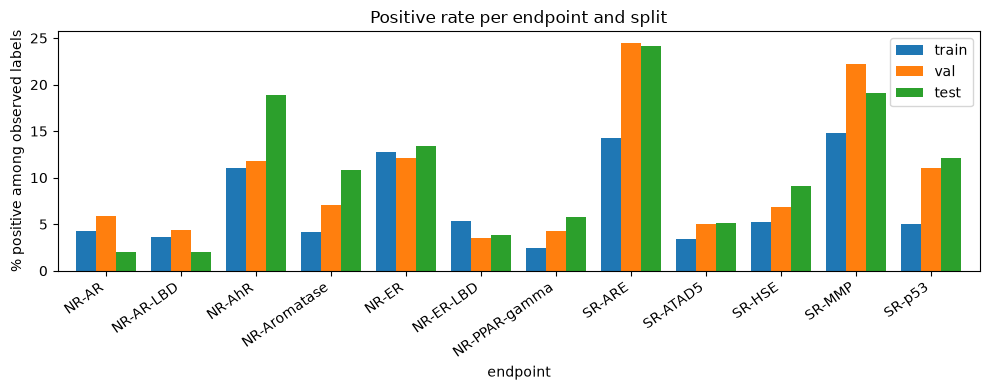

In [5]:
def label_counts(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for task in TASKS:
        y = df[task].to_numpy()
        observed = ~np.isnan(y)
        rows.append({"endpoint": task, "n_observed": int(observed.sum()), "n_positive": int((y == 1).sum()),
                     "n_negative": int((y == 0).sum()), "n_missing": int((~observed).sum())})
    return pd.DataFrame(rows).set_index("endpoint")

counts = pd.concat({s: label_counts(df) for s, df in splits.items()}, axis=1)
display(counts)

rate = pd.DataFrame({s: counts[s]["n_positive"] / counts[s]["n_observed"] * 100 for s in SPLITS})
ax = rate.plot.bar(figsize=(10, 4), width=0.8)
ax.set_ylabel("% positive among observed labels"); ax.set_title("Positive rate per endpoint and split")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

## 3. Shared metrics
ROC-AUC and PR-AUC (average precision) per endpoint, computed only on rows with an observed label. They are NaN when only one class is observed.
*(This stands in for Member 1's `src/evaluation/metrics.py`. Swap in the team version if it differs.)*

In [6]:
def compute_binary_metrics(y_true, y_prob) -> dict:
    y_true, y_prob = np.asarray(y_true, float), np.asarray(y_prob, float)
    observed = ~np.isnan(y_true)
    y, p = y_true[observed], y_prob[observed]
    n_pos, n_neg = int((y == 1).sum()), int((y == 0).sum())
    out = {"n_observed": int(observed.sum()), "n_positive": n_pos, "n_negative": n_neg,
           "roc_auc": np.nan, "pr_auc": np.nan}
    if n_pos and n_neg and not np.isnan(p).any():
        out["roc_auc"] = float(roc_auc_score(y, p))
        out["pr_auc"] = float(average_precision_score(y, p))
    return out

def evaluate_endpoints(y_true: np.ndarray, y_prob: np.ndarray) -> pd.DataFrame:
    return pd.DataFrame([{"endpoint": t, **compute_binary_metrics(y_true[:, j], y_prob[:, j])}
                         for j, t in enumerate(TASKS)])

## 4. Feature functions
Every feature function returns a `FeatureMatrix`: **row `i` of `X` belongs to `mol_ids[i]`**, column `j` is named `feature_names[j]`, and invalid SMILES are dropped from `X` and listed in `invalid` with a reason.

In [7]:
@dataclass
class FeatureMatrix:
    X: np.ndarray
    mol_ids: List[str]
    feature_names: List[str]
    invalid: pd.DataFrame = field(default_factory=lambda: pd.DataFrame(columns=["mol_id", "smiles", "reason"]))
    config: dict = field(default_factory=dict)

    def __post_init__(self):
        if self.X.ndim != 2 or self.X.shape != (len(self.mol_ids), len(self.feature_names)):
            raise ValueError(f"X shape {self.X.shape} does not match {len(self.mol_ids)} ids x {len(self.feature_names)} names")
        if len(set(self.mol_ids)) != len(self.mol_ids):
            raise ValueError("mol_ids must be unique")

    @property
    def shape(self):
        return self.X.shape

    def to_frame(self) -> pd.DataFrame:
        return pd.DataFrame(self.X, index=pd.Index(self.mol_ids, name="mol_id"), columns=self.feature_names)

    def subset(self, ids: Sequence[str]) -> "FeatureMatrix":
        position = {m: i for i, m in enumerate(self.mol_ids)}
        return FeatureMatrix(self.X[[position[m] for m in ids]], list(ids), self.feature_names, self.invalid, self.config)

    def align_labels(self, labels_df: pd.DataFrame) -> np.ndarray:
        """Label matrix in the same row order as X. NaN stays NaN."""
        return labels_df.set_index("mol_id").loc[self.mol_ids, TASKS].to_numpy(dtype=float)


def parse_smiles(smiles) -> Tuple[Optional[Chem.Mol], Optional[str]]:
    if not isinstance(smiles, str) or not smiles.strip():
        return None, "empty or non-string SMILES"
    RDLogger.DisableLog("rdApp.*")
    mol = Chem.MolFromSmiles(smiles)
    RDLogger.EnableLog("rdApp.*")
    if mol is None:
        return None, "RDKit could not parse or sanitize SMILES"
    if mol.GetNumAtoms() == 0:
        return None, "molecule has no atoms"
    return mol, None


def featurise(smiles: Sequence[str], mol_ids: Sequence[str], row_function, feature_names: List[str],
              config: dict, on_invalid: str = "drop", dtype=np.float64) -> FeatureMatrix:
    """Apply row_function(mol) to every valid molecule; handle invalid SMILES consistently."""
    smiles, mol_ids = list(smiles), [str(m) for m in mol_ids]
    if len(smiles) != len(mol_ids):
        raise ValueError("smiles and mol_ids must have the same length")
    if on_invalid not in ("drop", "raise"):
        raise ValueError("on_invalid must be 'drop' or 'raise'")
    rows, kept, bad = [], [], []
    for smi, mol_id in zip(smiles, mol_ids):
        mol, reason = parse_smiles(smi)
        if mol is None:
            bad.append({"mol_id": mol_id, "smiles": str(smi), "reason": reason})
        else:
            rows.append(row_function(mol)); kept.append(mol_id)
    invalid = pd.DataFrame(bad, columns=["mol_id", "smiles", "reason"])
    if bad:
        details = "; ".join(f"{b['mol_id']} ({b['reason']}): {b['smiles']!r}" for b in bad)
        if on_invalid == "raise":
            raise ValueError(f"{len(bad)} invalid molecule(s): {details}")
        logger.warning("Dropped %d invalid molecule(s): %s", len(bad), details)
    X = np.vstack(rows).astype(dtype) if rows else np.zeros((0, len(feature_names)), dtype)
    return FeatureMatrix(X, kept, feature_names, invalid, config)

### 4a. Morgan fingerprints
For each atom, the algorithm describes its neighbourhood out to `RADIUS` bonds and hashes each description to an integer. That integer is folded into one of `N_BITS` positions (`identifier mod N_BITS`). **A bit is 1 if at least one local substructure in the molecule maps to it.** Different substructures can share a bit (collisions). Similar molecules share many bits, so a model can link structural fragments to assay activity.

In [8]:
def compute_morgan_fingerprints(smiles, mol_ids, radius: int = RADIUS, n_bits: int = N_BITS,
                                on_invalid: str = "drop") -> FeatureMatrix:
    """Morgan bit vectors, X is uint8 with shape (n_valid, n_bits)."""
    if not isinstance(radius, int) or radius < 0 or not isinstance(n_bits, int) or n_bits < 1:
        raise ValueError("radius must be an int >= 0 and n_bits an int >= 1")
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=n_bits)
    width = len(str(n_bits - 1))
    names = [f"morgan_r{radius}_b{i:0{width}d}" for i in range(n_bits)]
    config = {"featurizer": "morgan", "radius": radius, "n_bits": n_bits, "use_chirality": False}
    return featurise(smiles, mol_ids, generator.GetFingerprintAsNumPy, names, config, on_invalid, np.uint8)

### 4b. Molecular descriptors
The five required descriptors (weight, LogP, H-bond donors and acceptors, TPSA) plus seven graph-based counts. Every one is computed from the 2-D molecular graph without 3-D coordinates or partial charges, so RDKit gives a value for every valid molecule. A failed or non-finite value becomes NaN. **The order below is fixed**, because saved models depend on it.

In [9]:
DESCRIPTORS = {
    "MolWt": (Descriptors.MolWt, "molecular weight (size)"),
    "MolLogP": (Crippen.MolLogP, "Wildman-Crippen LogP (lipophilicity)"),
    "NumHDonors": (Lipinski.NumHDonors, "hydrogen-bond donors"),
    "NumHAcceptors": (Lipinski.NumHAcceptors, "hydrogen-bond acceptors"),
    "TPSA": (rdMolDescriptors.CalcTPSA, "topological polar surface area (polarity)"),
    "NumRotatableBonds": (Lipinski.NumRotatableBonds, "rotatable bonds (flexibility)"),
    "RingCount": (rdMolDescriptors.CalcNumRings, "number of rings"),
    "NumAromaticRings": (rdMolDescriptors.CalcNumAromaticRings, "number of aromatic rings"),
    "HeavyAtomCount": (Lipinski.HeavyAtomCount, "non-hydrogen atoms (size)"),
    "NumHeteroatoms": (rdMolDescriptors.CalcNumHeteroatoms, "non-carbon, non-hydrogen atoms"),
    "FractionCSP3": (rdMolDescriptors.CalcFractionCSP3, "fraction of sp3 carbons (saturation)"),
    "FormalCharge": (Chem.GetFormalCharge, "net formal charge"),
}
DESCRIPTOR_NAMES = list(DESCRIPTORS)

def descriptors_from_mol(mol) -> np.ndarray:
    values = []
    for function, _ in DESCRIPTORS.values():
        try:
            value = float(function(mol))
        except Exception:
            value = math.nan
        values.append(value if math.isfinite(value) else math.nan)
    return np.array(values)

def compute_molecular_descriptors(smiles, mol_ids, on_invalid: str = "drop") -> FeatureMatrix:
    """Raw (unscaled) descriptors, X is float64 with shape (n_valid, 12)."""
    fm = featurise(smiles, mol_ids, descriptors_from_mol, [f"desc_{n}" for n in DESCRIPTOR_NAMES],
                   {"featurizer": "rdkit_descriptors", "descriptor_names": DESCRIPTOR_NAMES}, on_invalid)
    fm.config["non_finite_counts"] = {n: int(np.isnan(fm.X[:, j]).sum()) for j, n in enumerate(DESCRIPTOR_NAMES)}
    return fm

def make_descriptor_preprocessor() -> Pipeline:
    """Median imputation + standardisation. It lives inside the model pipeline, so it is fitted on training rows only."""
    return Pipeline([("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
                     ("scale", StandardScaler())])

pd.DataFrame([{"descriptor": n, "meaning": m} for n, (_, m) in DESCRIPTORS.items()])

,descriptor,meaning
0,MolWt,molecular weight (size)
1,MolLogP,Wildman-Crippen LogP (lipophilicity)
2,NumHDonors,hydrogen-bond donors
3,NumHAcceptors,hydrogen-bond acceptors
4,TPSA,topological polar surface area (polarity)
5,NumRotatableBonds,rotatable bonds (flexibility)
6,RingCount,number of rings
7,NumAromaticRings,number of aromatic rings
8,HeavyAtomCount,non-hydrogen atoms (size)
9,NumHeteroatoms,"non-carbon, non-hydrogen atoms"


In [10]:
def build_feature_matrix(df: pd.DataFrame, feature_set: str, on_invalid: str = "raise") -> FeatureMatrix:
    """on_invalid='raise' for the frozen splits: Member 1 already removed invalid SMILES, so every model must see the same molecules."""
    smiles, ids = df["smiles"].tolist(), df["mol_id"].astype(str).tolist()
    if feature_set == "morgan":
        return compute_morgan_fingerprints(smiles, ids, on_invalid=on_invalid)
    if feature_set == "descriptors":
        return compute_molecular_descriptors(smiles, ids, on_invalid=on_invalid)
    if feature_set == "morgan+descriptors":
        fp = compute_morgan_fingerprints(smiles, ids, on_invalid=on_invalid)
        desc = compute_molecular_descriptors(smiles, ids, on_invalid=on_invalid).subset(fp.mol_ids)
        return FeatureMatrix(np.hstack([fp.X.astype(np.float64), desc.X]), fp.mol_ids,
                             fp.feature_names + desc.feature_names, fp.invalid, {"parts": [fp.config, desc.config]})
    raise ValueError(f"Unknown feature set {feature_set!r}")

## 5. Look at the features on real molecules

,mol_id,smiles,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53
0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,0.0,0.0,1.0,NaN,NaN,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0
2,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN
3,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0
4,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


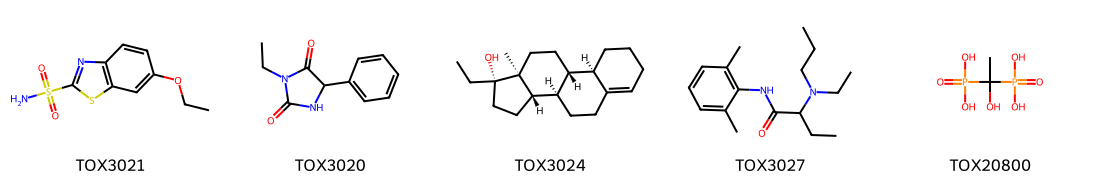

In [11]:
examples = splits["train"].head(5)
display(examples[["mol_id", "smiles"] + TASKS])
Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in examples["smiles"]], legends=list(examples["mol_id"]),
                     molsPerRow=5, subImgSize=(220, 180))

In [12]:
fp_train = build_feature_matrix(splits["train"], "morgan")
ex_fp = fp_train.subset(examples["mol_id"].tolist())
print("Fingerprint matrix (train):", fp_train.shape, "| rows in file order:", fp_train.mol_ids == splits["train"]["mol_id"].tolist())
bits = fp_train.X.sum(axis=1)
print(f"Bits set per molecule: median={np.median(bits):.0f}, min={bits.min()}, max={bits.max()}")
print(f"Bits never set in training: {(fp_train.X.sum(axis=0) == 0).sum()} of {N_BITS}")
pd.DataFrame({"mol_id": ex_fp.mol_ids, "bits set": ex_fp.X.sum(axis=1),
              "first set bits": [list(np.flatnonzero(r)[:8]) for r in ex_fp.X]})

Fingerprint matrix (train): (6166, 2048) | rows in file order: True
Bits set per molecule: median=24, min=1, max=118
Bits never set in training: 0 of 2048


,mol_id,bits set,first set bits
0,TOX3021,36,"[69, 80, 159, 162, 237, 294, 322, 350]"
1,TOX3020,28,"[5, 25, 27, 34, 80, 294, 301, 314]"
2,TOX3024,42,"[11, 57, 80, 159, 184, 284, 294, 345]"
3,TOX3027,36,"[1, 80, 294, 305, 381, 490, 552, 573]"
4,TOX20800,13,"[114, 149, 156, 192, 392, 486, 650, 807]"


### Which substructure set each bit? (first example molecule)

In [13]:
mol = Chem.MolFromSmiles(examples["smiles"].iloc[0])
generator = rdFingerprintGenerator.GetMorganGenerator(radius=RADIUS, fpSize=N_BITS)
info = rdFingerprintGenerator.AdditionalOutput(); info.AllocateBitInfoMap()
generator.GetFingerprint(mol, additionalOutput=info)
rows = []
for bit, envs in sorted(info.GetBitInfoMap().items()):
    for atom, radius in envs:
        env = Chem.FindAtomEnvironmentOfRadiusN(mol, radius, atom) if radius else None
        frag = Chem.MolToSmiles(Chem.PathToSubmol(mol, env)) if env else mol.GetAtomWithIdx(atom).GetSymbol()
        rows.append({"bit": bit, "centre atom": f"{mol.GetAtomWithIdx(atom).GetSymbol()}{atom}", "radius": radius, "substructure": frag})
print(examples["mol_id"].iloc[0], examples["smiles"].iloc[0])
pd.DataFrame(rows).head(15)

TOX3021 CCOc1ccc2nc(S(N)(=O)=O)sc2c1


,bit,centre atom,radius,substructure
0,69,O2,2,cc(c)OCC
1,80,C1,0,C
2,159,C8,2,cnc(sc)S(N)(=O)=O
3,162,S13,1,csc
4,237,C1,2,CCOc
5,294,C0,1,CC
6,322,C3,1,cc(c)O
7,350,S9,0,S
8,371,S9,2,nc(s)S(N)(=O)=O
9,378,N7,0,N


In [14]:
desc_train = build_feature_matrix(splits["train"], "descriptors")
print("Descriptor matrix (train):", desc_train.shape)
print("Non-finite values set to NaN:", {k: v for k, v in desc_train.config["non_finite_counts"].items() if v} or "none")
display(desc_train.subset(examples["mol_id"].tolist()).to_frame().round(3))
desc_train.to_frame().describe().T.round(2)

Descriptor matrix (train): (6166, 12)
Non-finite values set to NaN: none


,desc_MolWt,desc_MolLogP,desc_NumHDonors,desc_NumHAcceptors,desc_TPSA,desc_NumRotatableBonds,desc_RingCount,desc_NumAromaticRings,desc_HeavyAtomCount,desc_NumHeteroatoms,desc_FractionCSP3,desc_FormalCharge
mol_id,,,,,,,,,,,,
TOX3021,258.324,1.342,1.0,5.0,82.28,3.0,2.0,2.0,16.0,7.0,0.222,0.0
TOX3020,204.229,1.299,1.0,2.0,49.41,2.0,2.0,1.0,15.0,4.0,0.273,0.0
TOX3024,288.475,5.090,1.0,1.0,20.23,1.0,4.0,0.0,21.0,1.0,0.900,0.0
TOX3027,276.424,3.752,1.0,2.0,32.34,7.0,1.0,1.0,20.0,3.0,0.588,0.0
TOX20800,206.027,-0.992,5.0,3.0,135.29,2.0,0.0,0.0,11.0,9.0,1.000,0.0


,count,mean,std,min,25%,50%,75%,max
desc_MolWt,6166.0,245.96,139.93,9.01,152.72,212.40,304.64,1311.47
desc_MolLogP,6166.0,2.25,2.22,-17.41,1.06,2.23,3.46,22.61
desc_NumHDonors,6166.0,1.11,1.66,0.00,0.00,1.00,2.00,24.00
desc_NumHAcceptors,6166.0,3.05,2.70,0.00,1.00,2.00,4.00,40.00
desc_TPSA,6166.0,52.80,49.29,0.00,23.79,43.09,69.15,633.20
desc_NumRotatableBonds,6166.0,4.10,4.37,0.00,1.00,3.00,6.00,47.00
desc_RingCount,6166.0,1.44,4.08,0.00,0.00,1.00,2.00,264.00
desc_NumAromaticRings,6166.0,0.87,0.91,0.00,0.00,1.00,1.00,7.00
desc_HeavyAtomCount,6166.0,16.31,9.41,1.00,10.00,14.00,20.00,95.00
desc_NumHeteroatoms,6166.0,4.35,3.48,0.00,2.00,4.00,6.00,40.00


## 6. Logistic Regression baseline
* One binary model per endpoint, trained on **observed training labels only**.
* For each (C, class_weight) in the grid, fit on train and score on validation. Keep the best by validation ROC-AUC (ties go to higher PR-AUC, then smaller C). The test set has no role here.
* One class in the training labels → endpoint skipped (no model, probabilities NaN). One class in the validation labels → documented fallback `C=1, class_weight="balanced"`.
* Fingerprint bits are passed through unscaled. Descriptor columns are imputed and scaled inside the pipeline (fitted on train).

In [15]:
def build_lr_pipeline(C: float, class_weight, descriptor_columns: List[int], n_features: int) -> Pipeline:
    model = LogisticRegression(C=C, class_weight=class_weight, solver="lbfgs", max_iter=MAX_ITER, random_state=SEED)
    if not descriptor_columns:
        return Pipeline([("model", model)])
    if len(descriptor_columns) == n_features:
        return Pipeline([("preprocess", make_descriptor_preprocessor()), ("model", model)])
    preprocess = ColumnTransformer([("descriptors", make_descriptor_preprocessor(), descriptor_columns)],
                                   remainder="passthrough")
    return Pipeline([("preprocess", preprocess), ("model", model)])

def fit_pipeline(X, y, C, class_weight, descriptor_columns) -> Tuple[Pipeline, bool]:
    assert not np.isnan(y).any(), "only rows with an observed label may be used"
    pipeline = build_lr_pipeline(C, class_weight, descriptor_columns, X.shape[1])
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        pipeline.fit(X, y.astype(int))
    return pipeline, not any(issubclass(w.category, ConvergenceWarning) for w in caught)

def score_candidate(X_tr, y_tr, X_va, y_va, C, class_weight, descriptor_columns):
    pipeline, converged = fit_pipeline(X_tr, y_tr, C, class_weight, descriptor_columns)
    s = compute_binary_metrics(y_va, pipeline.predict_proba(X_va)[:, 1])
    return pipeline, {"C": C, "class_weight": class_weight or "none", "converged": converged,
                      "val_roc_auc": s["roc_auc"], "val_pr_auc": s["pr_auc"]}

def tune_endpoint(X_tr, y_tr, X_va, y_va, descriptor_columns):
    """Choose C and class_weight on validation. No test data is passed in."""
    if len(np.unique(y_va)) < 2:
        pipeline, converged = fit_pipeline(X_tr, y_tr, FALLBACK_PARAMS["C"], FALLBACK_PARAMS["class_weight"], descriptor_columns)
        return pipeline, {**FALLBACK_PARAMS, "status": "trained_fallback_params", "converged": converged}, pd.DataFrame()
    grid = [(C, cw) for C in C_GRID for cw in CLASS_WEIGHTS]
    results = Parallel(n_jobs=N_JOBS)(delayed(score_candidate)(X_tr, y_tr, X_va, y_va, C, cw, descriptor_columns)
                                      for C, cw in grid)
    log = pd.DataFrame([r for _, r in results])
    other = "pr_auc" if SELECTION_METRIC == "roc_auc" else "roc_auc"
    best = max(range(len(grid)), key=lambda i: (log.loc[i, f"val_{SELECTION_METRIC}"], log.loc[i, f"val_{other}"], -log.loc[i, "C"]))
    log["selected"] = log.index == best
    C, cw = grid[best]
    return results[best][0], {"C": C, "class_weight": cw, "status": "trained",
                              "converged": bool(log.loc[best, "converged"])}, log

In [16]:
FOLDER = {"morgan": "morgan", "descriptors": "descriptors", "morgan+descriptors": "morgan_descriptors"}

def run_feature_set(feature_set: str):
    features = {s: build_feature_matrix(splits[s], feature_set) for s in SPLITS}
    labels = {s: features[s].align_labels(splits[s]) for s in SPLITS}
    desc_cols = [j for j, n in enumerate(features["train"].feature_names) if n.startswith("desc_")]
    out_dir = MODEL_DIR / FOLDER[feature_set]; out_dir.mkdir(parents=True, exist_ok=True)
    info, models, logs = {}, {}, []

    # Phase 1: tune and fit with train + validation only
    for j, task in enumerate(TASKS):
        y_tr, y_va = labels["train"][:, j], labels["val"][:, j]
        tr, va = ~np.isnan(y_tr), ~np.isnan(y_va)
        base = {"n_train_observed": int(tr.sum()), "n_train_positive": int((y_tr == 1).sum()),
                "n_train_negative": int((y_tr == 0).sum()), "C": None, "class_weight": None,
                "converged": None, "model_file": None}
        if len(np.unique(y_tr[tr])) < 2:
            logger.warning("%s / %s: one class in training labels, skipped", feature_set, task)
            info[task] = {**base, "status": "skipped_single_class_train"}
            continue
        model, chosen, log = tune_endpoint(features["train"].X[tr], y_tr[tr], features["val"].X[va], y_va[va], desc_cols)
        if not log.empty:
            logs.append(log.assign(feature_set=feature_set, endpoint=task))
        joblib.dump(model, out_dir / f"{task}.joblib")
        models[task] = model
        info[task] = {**base, **chosen, "class_weight": chosen["class_weight"] or "none", "model_file": f"{task}.joblib"}

    # Phase 2: settings are frozen, now predict every split (test is used here for the first time)
    probs = {s: np.full(labels[s].shape, np.nan) for s in SPLITS}
    for j, task in enumerate(TASKS):
        if task in models:
            for s in SPLITS:
                probs[s][:, j] = models[task].predict_proba(features[s].X)[:, 1]

    metrics = pd.concat([evaluate_endpoints(labels[s], probs[s]).assign(split=s) for s in SPLITS], ignore_index=True)
    metrics["model"], metrics["feature_set"], metrics["selection_metric"] = "logistic_regression", feature_set, SELECTION_METRIC
    for col in ["status", "C", "class_weight", "converged"]:
        metrics[col] = metrics["endpoint"].map(lambda t: info[t][col])

    predictions = {s: pd.DataFrame({
        "model": "logistic_regression", "feature_set": feature_set, "split": s,
        "mol_id": np.repeat(features[s].mol_ids, len(TASKS)), "endpoint": np.tile(TASKS, len(features[s].mol_ids)),
        "y_true": labels[s].reshape(-1), "y_prob": probs[s].reshape(-1)}) for s in ["val", "test"]}

    manifest = {"model": "logistic_regression", "feature_set": feature_set, "endpoints": TASKS,
                "feature_config": {"morgan": {"radius": RADIUS, "n_bits": N_BITS, "use_chirality": False} if feature_set != "descriptors" else None,
                                   "descriptor_names": DESCRIPTOR_NAMES if feature_set != "morgan" else None,
                                   "n_features": features["train"].shape[1]},
                "endpoint_models": info, "selection_metric": SELECTION_METRIC, "c_grid": C_GRID,
                "class_weights": [c or "none" for c in CLASS_WEIGHTS], "fallback_params": FALLBACK_PARAMS,
                "seed": SEED, "refit_on_train_plus_val": False,
                "versions": {"rdkit": rdkit.__version__, "scikit-learn": sklearn.__version__}}
    (out_dir / "manifest.json").write_text(json.dumps(manifest, indent=2))
    return metrics, predictions, (pd.concat(logs, ignore_index=True) if logs else pd.DataFrame()), features

In [17]:
METRIC_COLUMNS = ["model", "feature_set", "endpoint", "split", "n_observed", "n_positive", "n_negative",
                  "roc_auc", "pr_auc", "status", "C", "class_weight", "selection_metric", "converged"]
(OUTPUT_DIR / "predictions").mkdir(parents=True, exist_ok=True)
all_metrics, all_logs, feature_store = [], [], {}
for fs in FEATURE_SETS:
    print(f"Training feature set: {fs} ...")
    m, preds, log, feats = run_feature_set(fs)
    all_metrics.append(m); all_logs.append(log); feature_store[fs] = feats
    for s, frame in preds.items():
        frame.to_csv(OUTPUT_DIR / "predictions" / f"lr_{FOLDER[fs]}_{s}.csv", index=False)

metrics = pd.concat(all_metrics, ignore_index=True)[METRIC_COLUMNS]
tuning_log = pd.concat(all_logs, ignore_index=True)
summary = (metrics.groupby(["model", "feature_set", "split"], sort=False)
           .agg(mean_roc_auc=("roc_auc", "mean"), mean_pr_auc=("pr_auc", "mean"), n_endpoints_evaluated=("roc_auc", "count"))
           .reset_index())
metrics.to_csv(OUTPUT_DIR / "lr_metrics.csv", index=False)
summary.to_csv(OUTPUT_DIR / "lr_summary.csv", index=False)
tuning_log.to_csv(OUTPUT_DIR / "lr_tuning_log.csv", index=False)
print("Statuses:", metrics.drop_duplicates(["feature_set", "endpoint"])["status"].value_counts().to_dict())
print("Non-converged tuning fits:", int((~tuning_log["converged"]).sum()), "of", len(tuning_log))

Training feature set: morgan ...


Training feature set: descriptors ...


Training feature set: morgan+descriptors ...


Statuses: {'trained': 36}
Non-converged tuning fits: 0 of 360


## 7. Results
Feature sets are compared on **validation**. Test scores are reported only after that choice.

In [18]:
summary.round(3)

,model,feature_set,split,mean_roc_auc,mean_pr_auc,n_endpoints_evaluated
0,logistic_regression,morgan,train,0.899,0.625,12
1,logistic_regression,morgan,val,0.724,0.323,12
2,logistic_regression,morgan,test,0.702,0.277,12
3,logistic_regression,descriptors,train,0.784,0.246,12
4,logistic_regression,descriptors,val,0.723,0.222,12
5,logistic_regression,descriptors,test,0.666,0.219,12
6,logistic_regression,morgan+descriptors,train,0.903,0.546,12
7,logistic_regression,morgan+descriptors,val,0.749,0.297,12
8,logistic_regression,morgan+descriptors,test,0.739,0.269,12


In [19]:
metrics.query("split == 'val'").pivot(index="endpoint", columns="feature_set", values=["roc_auc", "pr_auc"]).loc[TASKS].round(3)

roc_auc                                pr_auc                          
feature_set   descriptors morgan morgan+descriptors descriptors morgan morgan+descriptors
endpoint                                                                                 
NR-AR               0.773  0.747              0.785       0.176  0.556              0.556
NR-AR-LBD           0.771  0.808              0.804       0.159  0.416              0.348
NR-AhR              0.821  0.848              0.859       0.325  0.378              0.411
NR-Aromatase        0.627  0.660              0.670       0.104  0.142              0.120
NR-ER               0.617  0.650              0.639       0.170  0.334              0.236
NR-ER-LBD           0.758  0.778              0.813       0.103  0.426              0.201
NR-PPAR-gamma       0.706  0.596              0.675       0.103  0.069              0.104
SR-ARE              0.709  0.671              0.721       0.401  0.417              0.398
SR-ATAD5            0.617  0.696              0.677       0.127  0.177              0.145
SR-HSE              0.720  0.714              0.744       0.182  0.163              0.184
SR-MMP              0.854  0.818              0.866       0.571  0.564              0.609
SR-p53              0.703  0.702              0.730       0.238  0.234              0.253

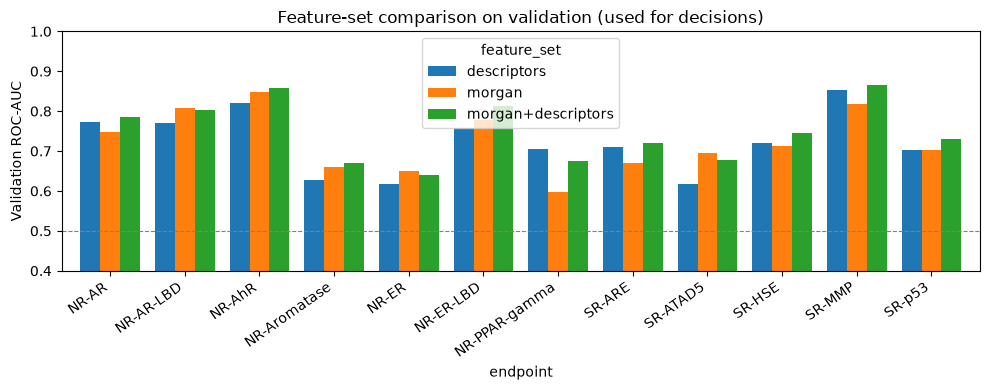

In [20]:
val = metrics.query("split == 'val'").pivot(index="endpoint", columns="feature_set", values="roc_auc").loc[TASKS]
ax = val.plot.bar(figsize=(10, 4), width=0.8)
ax.axhline(0.5, color="grey", lw=0.8, ls="--"); ax.set_ylim(0.4, 1)
ax.set_ylabel("Validation ROC-AUC"); ax.set_title("Feature-set comparison on validation (used for decisions)")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

In [21]:
best = summary.query("split == 'val'").sort_values("mean_roc_auc", ascending=False).iloc[0]
print(f"Highest mean validation ROC-AUC: {best.feature_set} ({best.mean_roc_auc:.3f})")
print("Its test scores, reported once after the choice:")
display(summary.query("split == 'test' and feature_set == @best.feature_set").round(3))
print("Per-endpoint test results for that feature set:")
metrics.query("split == 'test' and feature_set == @best.feature_set")[["endpoint", "n_observed", "n_positive", "n_negative", "roc_auc", "pr_auc"]].round(3)

Highest mean validation ROC-AUC: morgan+descriptors (0.749)
Its test scores, reported once after the choice:


,model,feature_set,split,mean_roc_auc,mean_pr_auc,n_endpoints_evaluated
8,logistic_regression,morgan+descriptors,test,0.739,0.269,12


Per-endpoint test results for that feature set:


,endpoint,n_observed,n_positive,n_negative,roc_auc,pr_auc
96,NR-AR,691,14,677,0.539,0.023
97,NR-AR-LBD,598,12,586,0.780,0.104
98,NR-AhR,582,110,472,0.814,0.529
99,NR-Aromatase,490,53,437,0.811,0.344
100,NR-ER,537,72,465,0.671,0.234
101,NR-ER-LBD,631,24,607,0.676,0.165
102,NR-PPAR-gamma,559,32,527,0.741,0.198
103,SR-ARE,497,120,377,0.744,0.466
104,SR-ATAD5,645,33,612,0.809,0.152
105,SR-HSE,605,55,550,0.738,0.298


In [22]:
print("Chosen C per endpoint:")
display(metrics.query("split == 'val'").pivot(index="endpoint", columns="feature_set", values="C").loc[TASKS])
few = counts["test"].query("n_positive < 20")
print("Endpoints with fewer than 20 test positives (noisy test AUC):", {k: int(v) for k, v in few["n_positive"].items()})

Chosen C per endpoint:


feature_set,descriptors,morgan,morgan+descriptors
endpoint,,,
NR-AR,0.01,1.000,0.010
NR-AR-LBD,10.00,0.010,0.010
NR-AhR,0.10,0.010,0.100
NR-Aromatase,10.00,0.100,0.100
NR-ER,1.00,0.001,0.010
NR-ER-LBD,10.00,0.010,0.010
NR-PPAR-gamma,0.01,1.000,0.001
SR-ARE,0.10,0.100,0.010
SR-ATAD5,10.00,0.010,0.010


Endpoints with fewer than 20 test positives (noisy test AUC): {'NR-AR': 14, 'NR-AR-LBD': 12}


**Caveats:** one split and one seed, with no confidence intervals, so small differences may not be meaningful. Validation and test contain only ring-containing molecules, because the scaffold split puts every acyclic molecule in train. This notebook does **not** show whether Logistic Regression is better or worse than the other models. That needs the RF, XGBoost and GNN results on the same split.

## 8. Predict new molecules with the saved models
SMILES should be standardised the same way as Member 1's data (largest fragment, canonical). Invalid inputs are reported, not silently dropped.

In [23]:
def predict_smiles(smiles, mol_ids=None, feature_set: str = "morgan"):
    folder = MODEL_DIR / FOLDER[feature_set]
    manifest = json.loads((folder / "manifest.json").read_text())
    ids = [str(i) for i in (mol_ids if mol_ids is not None else range(len(smiles)))]
    feats = build_feature_matrix(pd.DataFrame({"mol_id": ids, "smiles": list(smiles)}), feature_set, on_invalid="drop")
    assert feats.shape[1] == manifest["feature_config"]["n_features"]
    out = pd.DataFrame({"mol_id": feats.mol_ids})
    for task, meta in manifest["endpoint_models"].items():
        model = joblib.load(folder / meta["model_file"]) if meta["model_file"] else None
        out[f"prob_{task}"] = model.predict_proba(feats.X)[:, 1] if (model is not None and len(out)) else np.nan
    return out, feats.invalid

preds, invalid = predict_smiles(["CCO", "c1ccccc1O", "not_a_smiles"], ["ethanol", "phenol", "bad_input"])
display(preds.round(4)); invalid

,mol_id,prob_NR-AR,prob_NR-AR-LBD,prob_NR-AhR,prob_NR-Aromatase,prob_NR-ER,prob_NR-ER-LBD,prob_NR-PPAR-gamma,prob_SR-ARE,prob_SR-ATAD5,prob_SR-HSE,prob_SR-MMP,prob_SR-p53
0,ethanol,0.0030,0.1642,0.1266,0.0094,0.3905,0.0297,0.002,0.0660,0.0182,0.4517,0.1738,0.0272
1,phenol,0.0022,0.2353,0.5640,0.0262,0.6013,0.1595,0.046,0.3248,0.0541,0.5532,0.7722,0.0790


,mol_id,smiles,reason
0,bad_input,not_a_smiles,RDKit could not parse or sanitize SMILES


## 9. Sanity checks (all should print OK)

In [24]:
# fingerprint dimensions and configurability
fm = compute_morgan_fingerprints(["CCO", "c1ccccc1O"], ["a", "b"])
assert fm.shape == (2, 2048) and fm.X.dtype == np.uint8 and set(np.unique(fm.X)) <= {0, 1}
assert compute_morgan_fingerprints(["CCO"], ["a"], radius=3, n_bits=1024).shape == (1, 1024)

# row-to-ID alignment survives shuffling
ref = compute_morgan_fingerprints(["CCO", "c1ccccc1O", "CCN"], ["a", "b", "c"])
shuf = compute_morgan_fingerprints(["CCN", "CCO", "c1ccccc1O"], ["c", "a", "b"])
assert np.array_equal(shuf.subset(["a", "b", "c"]).X, ref.X)

# invalid SMILES are dropped and reported
fm = compute_morgan_fingerprints(["CCO", "xx", "", "C1CC"], ["ok", "bad", "empty", "open_ring"])
assert fm.mol_ids == ["ok"] and sorted(fm.invalid["mol_id"]) == ["bad", "empty", "open_ring"]

# descriptors: fixed order and a known value
d = compute_molecular_descriptors(["CCO"], ["ethanol"])
assert d.feature_names == [f"desc_{n}" for n in DESCRIPTOR_NAMES] and abs(d.X[0, 0] - 46.069) < 0.01

# every split featurised fully, rows aligned with the files
for fs, feats in feature_store.items():
    for s in SPLITS:
        assert feats[s].mol_ids == splits[s]["mol_id"].tolist(), (fs, s)
        assert feats[s].shape[0] == len(splits[s])

# missing labels were not used: training counts equal observed counts
train_counts = metrics.query("split == 'train'").drop_duplicates("endpoint").set_index("endpoint")["n_observed"]
assert (train_counts == counts["train"]["n_observed"]).all()

# saved predictions keep NaN where labels are missing
p = pd.read_csv(OUTPUT_DIR / "predictions" / "lr_morgan_test.csv")
assert p["y_true"].isna().sum() == counts["test"]["n_missing"].sum()
assert p["y_prob"].between(0, 1).all()
print("OK: all sanity checks passed")

OK: all sanity checks passed


## 10. Save the outputs
Writes the fingerprint matrices for Member 3, then zips `results/`, `models/` and `features/`. In Colab, set `DOWNLOAD = True` to download the zip.

Output files:
* `results/logistic_regression/lr_metrics.csv` has columns `model, feature_set, endpoint, split, n_observed, n_positive, n_negative, roc_auc, pr_auc, status, C, class_weight, selection_metric, converged`
* `results/logistic_regression/predictions/lr_<feature_set>_<split>.csv` has columns `model, feature_set, split, mol_id, endpoint, y_true, y_prob` (`y_true` is NaN where the label is missing)
* `models/logistic_regression/<feature_set>/<ENDPOINT>.joblib` holds a fitted scikit-learn pipeline, and `manifest.json` holds the feature settings and chosen hyperparameters

In [25]:
FEATURE_DIR.mkdir(exist_ok=True)
for s in SPLITS:
    for fs, tag in [("morgan", f"morgan_r{RADIUS}_b{N_BITS}"), ("descriptors", "descriptors")]:
        f = feature_store[fs][s]
        np.savez_compressed(FEATURE_DIR / f"{tag}_{s}.npz", X=f.X, mol_ids=np.array(f.mol_ids),
                            feature_names=np.array(f.feature_names), config_json=np.array(json.dumps(f.config)))

bundle_dir = Path("member2_outputs")
shutil.rmtree(bundle_dir, ignore_errors=True)
for folder in ["results", "models", "features"]:
    shutil.copytree(folder, bundle_dir / folder)
archive = shutil.make_archive("member2_outputs", "zip", bundle_dir)
print("Created", archive)

DOWNLOAD = False
if IN_COLAB and DOWNLOAD:
    colab_files.download(archive)

Created ./member2_outputs.zip
